# Figure 3 Supplement 6: Trial-to-trial variability and history dependence of the bound

Two questions about the trial-by-trial bound measurements, each answered by
comparing the real data with data simulated from each subject's stopping-model
fit, on the same trials in the same order and measured with the same pipeline:

**A — How much of the variability in the measured bounds is real?** The SD of
each subject's measured |bound| across trials (data, black) against the SD
expected from measurement alone: the model with its trial-to-trial bound
variability removed (`bound_cv` set to `NO_VAR_CV`), which keeps the discrete
pigeon steps, guesses, lapses, sensory noise and non-decision time. Points
above the identity line have variability beyond measurement. Blue: the full
model (with its fitted bound variability) against the same abscissa. Model SDs
are means over `SIM_REPS` simulated repetitions.

**B — Does the bound depend on the previous trial's outcome?** For each subject,
the change in |bound| on the trial after an error, as a fraction of the
subject's median |bound| in that block, controlling for the previous trial's
|bound| (`pigeon.adaptation.get_post_error_bound_effect`; the control keeps
carryover of the bound, together with errors being more common after low
bounds, from counting as a post-error effect). The model has no trial history,
so its coefficients show what noise alone produces. Black points: subjects;
black line: median. Light blue band: central 95% of individual subjects'
coefficients in the simulations; dark blue band: central 95% of the
across-subject median over simulated repetitions. P values: two-sided, data
median vs. the simulated medians.

Columns: OL low-SNR blocks 1–3 (the error penalty differs by block: none,
coins, steps). Trials serving as trial n: the standard filter
(`get_good_trial_array`: DT ≥ 2, trial_number ≥ 10 and the adaptation
exclusion, no wall hit, RT cutoff), finite nonzero bound, raw positions (no
bias correction) for data and model. A: subjects need ≥ `MIN_TRIALS` such
trials. B: subjects need ≥ `MIN_POST_ERROR` post-error trials; when the
previous trial's bound is unmeasurable (e.g. a one-step guess) the subject's
mean is imputed for the control (counts printed). Subject-blocks whose plateau
sits at a fit limit are left out (counts printed).

The lag-1 autocorrelation of |bound| is reported in the caption only: it is
slightly higher than the model's (by ≈ 0.05; median percentile within each
subject's simulations 0.64–0.70, Wilcoxon p = 0.04, 0.006, 0.008), i.e. a small
carryover from one trial to the next.

Replaces the old Figure03S04 (archived in `notebooks/archive/`), which used a
fixed-bound simulation as the comparison.


In [1]:
import sys
sys.path.insert(0, '..')

from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import numpy as np
import pandas as pd
import scipy.stats

from pigeon.adaptation import get_post_error_bound_effect, get_sequential_bound_stats
from pigeon.data import get_good_trial_array
from pigeon.pathDefaults import FIGURES_DIR
from pigeon.plotting import FONT_RC, add_panel_label
from pigeon.stopping import (get_plateau_at_limit, get_stopping_model_trials, infer_bounds_like_data,
                             simulate_stopping_data_table)

PROCESSED = Path('../data/processed')

In [2]:
SIM_REPS = 100
SIM_SEED = 13
NO_VAR_CV = 1e-3      # bound_cv for the measurement-only model (0 itself is not a valid gamma CV)
MIN_TRIALS = 20
MIN_POST_ERROR = 3
BLOCKS = ['B1', 'B2', 'B3']
BLOCK_TITLES = {'B1': 'No penalty', 'B2': 'Coin penalty', 'B3': 'Step penalty'}

trials_all = get_stopping_model_trials('OL', [1, 2, 3, 4, 5, 6])
trials = trials_all[trials_all.condition.isin(BLOCKS)].copy()
fits = pd.read_pickle(PROCESSED / 'stopping_fits_main.pkl')
fits = fits[(fits.task == 'OL') & fits.group.isin(BLOCKS)]
rng = np.random.default_rng(SIM_SEED)
sims = {}
for name, f in {'full': fits, 'no_var': fits.assign(bound_cv=NO_VAR_CV)}.items():
    s = simulate_stopping_data_table(trials, f, group_col='condition', num_reps=SIM_REPS, rng=rng)
    sims[name] = infer_bounds_like_data(s)    # keeps each simulated trial's real trial_number

def _with_measured(t):
    """All trials, with abs_bound set to NaN where the trial's bound is not used."""
    lg = get_good_trial_array(t, min_dt=2) & np.isfinite(t.bound) & (t.bound != 0)
    return t.assign(abs_bound=t.bound.abs().where(lg))

real_t = _with_measured(trials)
sim_t = {k: _with_measured(v) for k, v in sims.items()}
KEYS = ['subject_index', 'condition']

at_limit = pd.MultiIndex.from_frame(fits.loc[get_plateau_at_limit(fits), ['subject_index', 'group']])

# A: SDs of the measured |bound|
sd = get_sequential_bound_stats(real_t, group_cols=KEYS, min_trials=MIN_TRIALS)[['n_trials', 'sd']]
for k, t in sim_t.items():
    sd[f'sd_{k}'] = get_sequential_bound_stats(t, group_cols=KEYS + ['rep'], min_trials=MIN_TRIALS) \
        .sd.groupby(level=KEYS).mean()
l_lim = sd.index.isin(at_limit)
print(f'excluded {int(l_lim.sum())} subject-blocks with the plateau at a fit limit: {list(sd.index[l_lim])}')
sd = sd[~l_lim]

# B: post-error effect
pe_real = get_post_error_bound_effect(real_t, group_cols=KEYS, min_post_error=MIN_POST_ERROR)
pe_real = pe_real[~pe_real.index.isin(at_limit)]
pe_sim = get_post_error_bound_effect(sim_t['full'], group_cols=KEYS + ['rep'], min_post_error=MIN_POST_ERROR)
pe_sim = pe_sim[~pe_sim.droplevel('rep').index.isin(at_limit)]
# Simulated subject-blocks use only the subjects that enter the real comparison
pe_sim = pe_sim[pe_sim.droplevel('rep').index.isin(pe_real.dropna(subset=['post_error_effect']).index)]

rows = []
for b in BLOCKS:
    g = sd.xs(b, level='condition').dropna()
    r = pe_real.xs(b, level='condition')
    x = r.post_error_effect.dropna()
    sim_med = pe_sim.xs(b, level='condition').post_error_effect.groupby(level='rep').median()
    dev = np.abs(sim_med - sim_med.mean())
    p = (1 + (dev >= abs(x.median() - sim_med.mean())).sum()) / (1 + len(sim_med))
    rows.append({'block': b, 'A subjects': len(g),
                 'SD data': g.sd.median(), 'SD measurement only': g.sd_no_var.median(), 'SD full model': g.sd_full.median(),
                 'fraction of data variance beyond measurement': (1 - g.sd_no_var ** 2 / g.sd ** 2).median(),
                 'data SD > measurement-only SD': f'{int((g.sd > g.sd_no_var).sum())}/{len(g)}',
                 'Wilcoxon p (data vs. full model SD)': scipy.stats.wilcoxon(g.sd, g.sd_full).pvalue,
                 'B subjects': len(x), f'B excluded (< {MIN_POST_ERROR} post-error trials)': int(r.post_error_effect.isna().sum()),
                 'median post-error trials': r.n_post_error[x.index].median(),
                 'prev bound imputed (fraction of trials)': r.n_prev_imputed[x.index].sum() / r.n_trials[x.index].sum(),
                 'post-error effect, median': x.median(), 'simulated medians, 95%': f'[{sim_med.quantile(.025):.3f}, {sim_med.quantile(.975):.3f}]',
                 'p (vs. simulated medians)': p})
    print(f'{b}: {int((sd.xs(b, level="condition").n_trials < MIN_TRIALS).sum())} subjects with < {MIN_TRIALS} usable trials (no SD)')
summary = pd.DataFrame(rows).set_index('block').T
display(summary)


OL: subjects with a good adaptation tau fit, by block: {1: 2, 2: 25, 3: 9, 4: 18, 5: 8, 6: 9}
OL: 42,252 trials in blocks [1, 2, 3, 4, 5, 6]; excluded 3,240 with trial_number < 10, 225 more in the adaptation transient, 364 more with no choice; 60 subjects


excluded 5 subject-blocks with the plateau at a fit limit: [(13, 'B3'), (44, 'B3'), (51, 'B1'), (51, 'B2'), (59, 'B1')]


B1: 6 subjects with < 20 usable trials (no SD)
B2: 7 subjects with < 20 usable trials (no SD)
B3: 14 subjects with < 20 usable trials (no SD)


block,B1,B2,B3
A subjects,52,52,43
SD data,0.116992,0.123842,0.118992
SD measurement only,0.114041,0.125344,0.119751
SD full model,0.120472,0.132653,0.126599
fraction of data variance beyond measurement,0.071725,-0.000035,0.055754
data SD > measurement-only SD,30/52,26/52,27/43
Wilcoxon p (data vs. full model SD),0.357678,0.002282,0.136984
B subjects,53,50,42
B excluded (< 3 post-error trials),5,9,15
median post-error trials,16.0,9.5,5.5


1 extra bytes in post.stringData array


'created' timestamp seems very low; regarding as unix timestamp


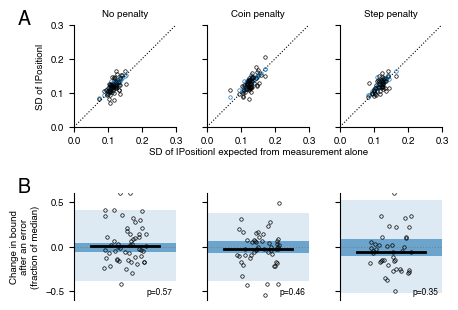

Saved /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Figures/Figure03_S06.pdf (+ .png)


In [3]:
CM = 1 / 2.54
FS = 7
plt.rcParams.update({'font.size': FS, 'axes.labelsize': FS, 'axes.titlesize': FS, **FONT_RC})
MODEL = 'tab:blue'
SD_LIM = (0, 0.3)
PE_LIM = (-0.6, 0.6)

fig = plt.figure(figsize=(11 * CM, 8.5 * CM))
gs = gridspec.GridSpec(2, 3, figure=fig, hspace=0.6, wspace=0.3, left=0.13, right=0.98, bottom=0.1, top=0.93)
axes = np.array([[fig.add_subplot(gs[r, c]) for c in range(3)] for r in range(2)])
jitter = np.random.default_rng(0)
for c, b in enumerate(BLOCKS):
    # A
    ax = axes[0, c]
    g = sd.xs(b, level='condition').dropna()
    ax.plot(SD_LIM, SD_LIM, 'k:', lw=0.8)
    ax.plot(g.sd_no_var, g.sd_full, 'o', color=MODEL, mfc='none', ms=2.5, mew=0.5)
    ax.plot(g.sd_no_var, g.sd, 'ko', mfc='none', ms=2.5, mew=0.5)
    ax.set_xlim(SD_LIM)
    ax.set_ylim(SD_LIM)
    ax.set_xticks([0, 0.1, 0.2, 0.3])
    ax.set_yticks([0, 0.1, 0.2, 0.3])
    ax.set_box_aspect(1)
    ax.set_title(BLOCK_TITLES[b])
    # B
    ax = axes[1, c]
    x = pe_real.xs(b, level='condition').post_error_effect.dropna()
    s = pe_sim.xs(b, level='condition').post_error_effect.dropna()
    sim_med = s.groupby(level='rep').median()
    ax.axhspan(*s.quantile([.025, .975]), color=MODEL, alpha=0.15, lw=0)
    ax.axhspan(*sim_med.quantile([.025, .975]), color=MODEL, alpha=0.6, lw=0)
    ax.axhline(0, color='0.5', ls=':', lw=0.8)
    ax.plot(jitter.uniform(-0.25, 0.25, len(x)), x.clip(*PE_LIM), 'ko', mfc='none', ms=2.5, mew=0.5)
    ax.plot([-0.4, 0.4], [x.median()] * 2, 'k-', lw=2)
    p = summary.loc['p (vs. simulated medians)', b]
    ax.text(0.96, 0.04, f'p{"<0.01" if p < 0.01 else f"={p:.2f}"}', transform=ax.transAxes, ha='right',
            va='bottom', fontsize=6)
    ax.set_xlim(-0.6, 0.6)
    ax.set_ylim(PE_LIM)
    ax.set_xticks([])
    ax.spines['bottom'].set_visible(False)
    ax.set_yticks([-0.5, 0, 0.5])
    for r in range(2):
        axes[r, c].spines[['top', 'right']].set_visible(False)
        if c > 0:
            axes[r, c].set_yticklabels([])
axes[0, 0].set_ylabel('SD of |Position|')
axes[1, 0].set_ylabel('Change in bound\nafter an error\n(fraction of median)')

def _row_xlabel(axs, label):
    fig.canvas.draw()
    left, right = axs[0].get_position().x0, axs[-1].get_position().x1
    bottom = min(a.get_tightbbox().transformed(fig.transFigure.inverted()).y0 for a in axs)
    fig.text((left + right) / 2, bottom - 0.004, label, ha='center', va='top', fontsize=FS)

_row_xlabel(axes[0], 'SD of |Position| expected from measurement alone')
for r, letter in enumerate('AB'):
    add_panel_label(axes[r, 0], letter, dx=-0.55, dy=1.15)

out = FIGURES_DIR / 'Figure03_S06.pdf'
fig.savefig(out, dpi=300, bbox_inches='tight')
fig.savefig(out.with_suffix('.png'), dpi=300, bbox_inches='tight')
plt.show()
print(f'Saved {out} (+ .png)')


## Interpretation

(Filled in after review.)